**Introducción a la Ciencia de Datos 2026**
Posgrado en Ciencias de la Computación - CICESE

# Tarea · Diseñar una CNN compacta con Global Average Pooling

**Objetivo.** Diseñar una CNN con *Global Average Pooling* (GAP) que supere el **95 %** de exactitud en validación en MNIST con **menos de 54 330 parámetros entrenables**, que es el total de la CNN base con Flatten. Entre las variantes que cumplen ambos requisitos se elige la de menos parámetros. Después se mide cómo cambia su exactitud cuando los dígitos se desplazan.

El notebook reutiliza las particiones de la sesión 21 (8000 imágenes de entrenamiento, 1500 de validación y 2000 de prueba, semilla 42), el margen negro de 4 píxeles, la función `entrenar` (Adam, tasa 0.001, lote 128, 20 épocas) y la función `desplazar`.

```

## 1. Datos y funciones comunes

Esta celda reproduce sin cambios la preparación de datos del notebook de clase.

In [1]:
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from tensorflow import keras

SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()
i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)

def preparar_imagenes(imagenes):
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0

X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]
for nombre, X in [("Entrenamiento", X_ent), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre}: {X.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (8000, 36, 36, 1)
Validación: (1500, 36, 36, 1)
Prueba: (2000, 36, 36, 1)


Las funciones `crear_cnn`, `lotes`, `entrenar`, `resumen_modelo`, `desplazar` y `predecir` son las del notebook de clase. Se copian sin modificar para que la configuración de entrenamiento sea idéntica en todas las variantes.

In [2]:
CAPAS = (16, 16)
LOTE = 128
EPOCAS = 20
TASA = 0.001

def crear_cnn(filtros=CAPAS, padding="same", pooling="max", stride=1, cabeza="flatten"):
    capas = [keras.Input(shape=FORMA)]
    for i, n_filtros in enumerate(filtros):
        capas.append(keras.layers.Conv2D(
            n_filtros, 3, strides=stride if i == 0 else 1,
            padding=padding, activation="relu", name=f"conv_{i + 1}",
        ))
    if pooling == "max":
        capas.append(keras.layers.MaxPooling2D(2, name="pool"))
    elif pooling == "average":
        capas.append(keras.layers.AveragePooling2D(2, name="pool"))
    elif pooling != "sin":
        raise ValueError("pooling debe ser 'max', 'average' o 'sin'")

    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    else:
        raise ValueError("cabeza debe ser 'flatten' o 'gap'")

    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name=f"cnn_{cabeza}")

def lotes(X, y=None, mezclar=False):
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)

def entrenar(constructor, **configuracion):
    keras.utils.set_random_seed(SEMILLA)
    modelo = constructor(**configuracion)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historial = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True),
        validation_data=lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False,  # lotes() ya mezcla los datos
    ).history
    return modelo, historial

def parametros_entrenables(modelo):
    return sum(int(np.prod(v.shape)) for v in modelo.trainable_weights)

def resumen_modelo(nombre, modelo, historial):
    return {
        "Modelo": nombre,
        "Parámetros entrenables": parametros_entrenables(modelo),
        "Exactitud validación (%)": 100 * historial["val_accuracy"][-1],
    }

def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado

def predecir(modelo, imagenes):
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)

## 2. Recuperar los modelos de referencia

Se reentrenan la CNN base con Flatten y la CNN base con GAP con la misma configuración. Ambas tienen dos convoluciones de 16 filtros de 3 × 3, *padding same* y un *max pooling* de 2 × 2 al final. La tabla las compara con la ejecución guardada del notebook de clase. Puede haber diferencias pequeñas por el hardware o la versión de TensorFlow.

In [3]:
REFERENCIA = pd.DataFrame({
    "Modelo": ["CNN + Flatten", "CNN + GAP"],
    "Parámetros (guardado)": [54330, 2650],
    "Validación guardada (%)": [96.87, 44.07],
    "Prueba 0 px guardada (%)": [97.15, 46.35],
    "Prueba 4 px guardada (%)": [37.21, 46.38],
})

inicio = time.time()
modelo_flatten, hist_flatten = entrenar(crear_cnn, cabeza="flatten")
modelo_gap_base, hist_gap_base = entrenar(crear_cnn, cabeza="gap")
print(f"Tiempo: {time.time() - inicio:.0f} s")

PARAMS_FLATTEN = parametros_entrenables(modelo_flatten)
tabla_ref = REFERENCIA.copy()
tabla_ref["Parámetros (esta ejecución)"] = [PARAMS_FLATTEN, parametros_entrenables(modelo_gap_base)]
tabla_ref["Validación esta ejecución (%)"] = [
    100 * hist_flatten["val_accuracy"][-1], 100 * hist_gap_base["val_accuracy"][-1],
]
display(tabla_ref.round(2))

Tiempo: 478 s


,Modelo,Parámetros (guardado),Validación guardada (%),Prueba 0 px guardada (%),Prueba 4 px guardada (%),Parámetros (esta ejecución),Validación esta ejecución (%)
0,CNN + Flatten,54330,96.87,97.15,37.21,54330,96.80
1,CNN + GAP,2650,44.07,46.35,46.38,2650,43.93


## 3. Variantes con GAP

### Por qué falla el GAP base

GAP promedia cada canal sobre todas las posiciones del mapa. El resultado indica **cuánto** aparece un patrón en la imagen, pero no **dónde**. En la CNN base, cada unidad del último mapa mira una ventana de solo **6 × 6 píxeles** de la entrada de 36 × 36 (su **campo receptivo**). Esa ventana basta para detectar trazos y bordes, pero no la forma completa del dígito. Promediar detectores tan locales produce algo parecido a un histograma de trazos. Muchos dígitos comparten trazos, por ejemplo un 6 y un 9, y el modelo los confunde. Flatten no tiene ese problema porque conserva la posición de cada activación, pero a cambio necesita 51 850 pesos en la capa densa.

**Hipótesis.** Si GAP falla porque sus canales ven poco de la imagen, conviene **agrandar el campo receptivo** antes de promediar. La forma más barata es intercalar *pooling* entre convoluciones, porque cada pooling duplica el paso con que avanzan las capas siguientes sobre la imagen. También ayuda añadir convoluciones. Cuando los canales finales responden a partes grandes del dígito, como un lazo cerrado arriba o un trazo vertical largo, saber cuánto aparece cada parte ya permite distinguir las clases.

### Familia de arquitecturas

Cada variante es una secuencia de **etapas**. Una etapa tiene una o más convoluciones con ReLU y *padding same*, seguidas de un *max pooling* de 2 × 2. Después de la última etapa va GAP y una capa densa de 10 clases con softmax. La notación `16 | 32` significa dos etapas, con una convolución de 16 filtros y otra de 32. `16-16` dentro de una etapa significa dos convoluciones seguidas antes del pooling.

Con 36 × 36 de entrada, los mapas miden 18 × 18 después de una etapa, 9 × 9 después de dos, 4 × 4 después de tres y 2 × 2 después de cuatro.

Las variantes están organizadas en **comparaciones que cambian una sola decisión**:

- **C1 · Ubicación del pooling, con 2 650 parámetros.** GAP base (`16-16`, pooling al final) frente a `16 | 16` (pooling entre convoluciones).
- **C2 · Ubicación del pooling, con 7 290 parámetros.** `16-16-16-16` (pooling al final) frente a `16-16 | 16-16`.
- **C3 · Número de etapas (profundidad con pooling).** `16 | 16` → `16 | 16 | 16` → `16 | 16 | 16 | 16`.
- **C4 · Filtros de la primera convolución.** `8 | 16 | 16` frente a `16 | 16 | 16`.
- **C5 · Tamaño del kernel de la primera convolución.** `16 | 16 | 16` con 3 × 3 frente a 5 × 5.
- **C6 · Filtros de las etapas profundas.** `16 | 16 | 16` frente a `16 | 32 | 32`.

En C1 y C2, las dos variantes tienen **exactamente los mismos parámetros**, porque el pooling no tiene pesos. Cualquier diferencia de exactitud se debe solo a dónde se reduce la resolución.

Se añaden tres variantes para acotar el tamaño mínimo: `8 | 8 | 8` y `8 | 8 | 16`, que son más pequeñas, y `16 | 32 | 64`, una variante amplia que sirve de control por si ninguna pequeña llega al 95 %.

In [4]:
def crear_gap(etapas, kernel_inicial=3):
    """CNN con GAP. `etapas` es una lista de tuplas de filtros; cada etapa termina en MaxPooling 2 × 2."""
    capas = [keras.Input(shape=FORMA)]
    primera = True
    for e, filtros in enumerate(etapas, start=1):
        for j, n_filtros in enumerate(filtros, start=1):
            capas.append(keras.layers.Conv2D(
                n_filtros, kernel_inicial if primera else 3, padding="same",
                activation="relu", name=f"conv_{e}_{j}",
            ))
            primera = False
        capas.append(keras.layers.MaxPooling2D(2, name=f"pool_{e}"))
    capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name="cnn_gap")

def campo_receptivo(etapas, kernel_inicial=3):
    """Lado del campo receptivo (en píxeles de entrada) de una unidad del último mapa."""
    r, salto, primera = 1, 1, True
    for filtros in etapas:
        for _ in filtros:
            k = kernel_inicial if primera else 3
            r += (k - 1) * salto
            primera = False
        r += (2 - 1) * salto  # max pooling 2 × 2 con stride 2
        salto *= 2
    return r

def notacion(etapas, kernel_inicial=3):
    texto = " | ".join("-".join(str(f) for f in etapa) for etapa in etapas)
    return texto + (f"  (kernel {kernel_inicial}×{kernel_inicial} en conv 1)" if kernel_inicial != 3 else "")

VARIANTES = {
    "V1": dict(etapas=[(16,), (16,)]),
    "V2": dict(etapas=[(16, 16, 16, 16)]),
    "V3": dict(etapas=[(16, 16), (16, 16)]),
    "V4": dict(etapas=[(16,), (16,), (16,)]),
    "V5": dict(etapas=[(16,), (16,), (16,), (16,)]),
    "V6": dict(etapas=[(8,), (16,), (16,)]),
    "V7": dict(etapas=[(16,), (16,), (16,)], kernel_inicial=5),
    "V8": dict(etapas=[(16,), (32,), (32,)]),
    "V9": dict(etapas=[(8,), (8,), (8,)]),
    "V10": dict(etapas=[(8,), (8,), (16,)]),
    "V11": dict(etapas=[(16,), (32,), (64,)]),
}
BASE_GAP = dict(etapas=[(16, 16)])  # misma arquitectura que crear_cnn(cabeza="gap")

def describir(clave, config):
    modelo = crear_gap(**config)
    forma = modelo.get_layer("vector").input.shape[1:]
    return {
        "Variante": clave,
        "Arquitectura": notacion(**config),
        "Convoluciones": sum(len(e) for e in config["etapas"]),
        "Poolings": len(config["etapas"]),
        "Mapa antes de GAP": " × ".join(str(d) for d in forma),
        "Campo receptivo (px)": campo_receptivo(**config),
        "Parámetros entrenables": parametros_entrenables(modelo),
    }

descripcion = pd.DataFrame(
    [describir("GAP base", BASE_GAP)] + [describir(k, c) for k, c in VARIANTES.items()]
).set_index("Variante")
assert descripcion.loc["GAP base", "Parámetros entrenables"] == parametros_entrenables(modelo_gap_base)
display(descripcion)

,Arquitectura,Convoluciones,Poolings,Mapa antes de GAP,Campo receptivo (px),Parámetros entrenables
Variante,,,,,,
GAP base,16-16,2,1,18 × 18 × 16,6,2650
V1,16 | 16,2,2,9 × 9 × 16,10,2650
V2,16-16-16-16,4,1,18 × 18 × 16,10,7290
V3,16-16 | 16-16,4,2,9 × 9 × 16,16,7290
V4,16 | 16 | 16,3,3,4 × 4 × 16,22,4970
V5,16 | 16 | 16 | 16,4,4,2 × 2 × 16,46,7290
V6,8 | 16 | 16,3,3,4 × 4 × 16,22,3738
V7,16 | 16 | 16 (kernel 5×5 en conv 1),3,3,4 × 4 × 16,24,5226
V8,16 | 32 | 32,3,3,4 × 4 × 32,22,14378


Las once variantes se entrenan con `entrenar`, la misma función que los modelos base. Se registra la exactitud de validación **al final de la época 20**. La mejor época se muestra solo como información y no se usa para elegir.

In [5]:
historiales = {"GAP base": hist_gap_base}
modelos_gap = {"GAP base": modelo_gap_base}
inicio = time.time()
for clave, config in VARIANTES.items():
    t0 = time.time()
    modelos_gap[clave], historiales[clave] = entrenar(crear_gap, **config)
    print(f"{clave:>4} · {notacion(**config):<34} "
          f"val = {100 * historiales[clave]['val_accuracy'][-1]:6.2f} %  ({time.time() - t0:.0f} s)")
print(f"Tiempo total: {time.time() - inicio:.0f} s")

UMBRAL_VAL = 95.0
tabla_val = descripcion.copy()
tabla_val["Exactitud validación ép. 20 (%)"] = [100 * historiales[k]["val_accuracy"][-1] for k in tabla_val.index]
tabla_val["Mejor época (%)"] = [100 * max(historiales[k]["val_accuracy"]) for k in tabla_val.index]
tabla_val["Exactitud entrenamiento ép. 20 (%)"] = [100 * historiales[k]["accuracy"][-1] for k in tabla_val.index]
tabla_val["Cumple"] = (
    (tabla_val["Exactitud validación ép. 20 (%)"] > UMBRAL_VAL)
    & (tabla_val["Parámetros entrenables"] < PARAMS_FLATTEN)
)
tabla_val = tabla_val.sort_values("Parámetros entrenables")
display(tabla_val[["Arquitectura", "Mapa antes de GAP", "Campo receptivo (px)",
                   "Parámetros entrenables", "Exactitud validación ép. 20 (%)",
                   "Mejor época (%)", "Exactitud entrenamiento ép. 20 (%)", "Cumple"]].round(2))

  V1 · 16 | 16                            val =  61.80 %  (126 s)
  V2 · 16-16-16-16                        val =  61.20 %  (553 s)
  V3 · 16-16 | 16-16                      val =  88.33 %  (311 s)
  V4 · 16 | 16 | 16                       val =  90.07 %  (133 s)
  V5 · 16 | 16 | 16 | 16                  val =  95.53 %  (140 s)
  V6 · 8 | 16 | 16                        val =  91.53 %  (99 s)
  V7 · 16 | 16 | 16  (kernel 5×5 en conv 1) val =  90.47 %  (167 s)
  V8 · 16 | 32 | 32                       val =  93.47 %  (148 s)
  V9 · 8 | 8 | 8                          val =  81.13 %  (89 s)
 V10 · 8 | 8 | 16                         val =  89.20 %  (89 s)
 V11 · 16 | 32 | 64                       val =  95.33 %  (165 s)
Tiempo total: 2019 s


,Arquitectura,Mapa antes de GAP,Campo receptivo (px),Parámetros entrenables,Exactitud validación ép. 20 (%),Mejor época (%),Exactitud entrenamiento ép. 20 (%),Cumple
Variante,,,,,,,,
V9,8 | 8 | 8,4 × 4 × 8,22,1338,81.13,81.13,81.41,False
V10,8 | 8 | 16,4 × 4 × 16,22,2002,89.20,89.20,89.00,False
GAP base,16-16,18 × 18 × 16,6,2650,43.93,44.73,45.21,False
V1,16 | 16,9 × 9 × 16,10,2650,61.80,62.13,64.65,False
V6,8 | 16 | 16,4 × 4 × 16,22,3738,91.53,91.53,91.05,False
V4,16 | 16 | 16,4 × 4 × 16,22,4970,90.07,90.07,90.30,False
V7,16 | 16 | 16 (kernel 5×5 en conv 1),4 × 4 × 16,24,5226,90.47,90.53,90.47,False
V2,16-16-16-16,18 × 18 × 16,10,7290,61.20,65.47,64.88,False
V5,16 | 16 | 16 | 16,2 × 2 × 16,46,7290,95.53,95.53,95.91,True


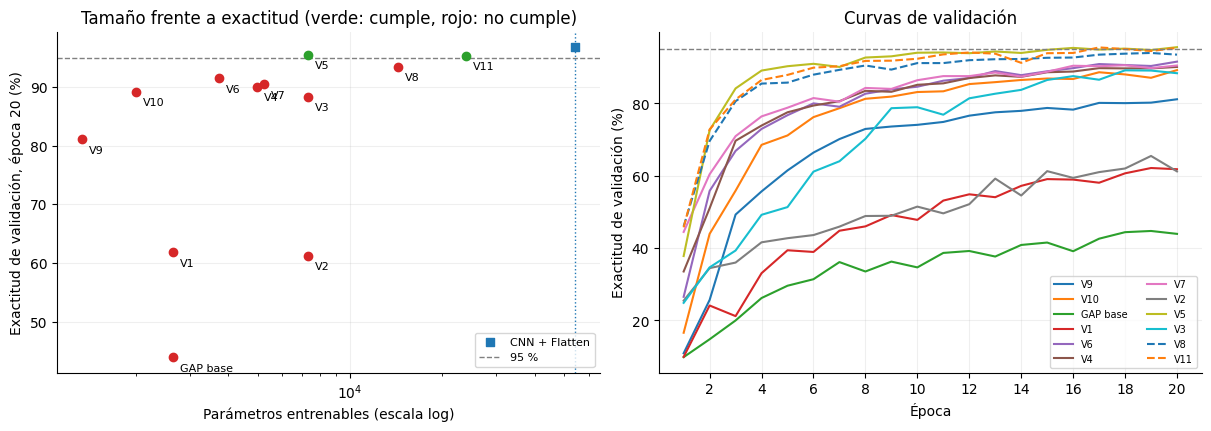

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")

ax = ejes[0]
for clave in tabla_val.index:
    p = tabla_val.loc[clave, "Parámetros entrenables"]
    acc = tabla_val.loc[clave, "Exactitud validación ép. 20 (%)"]
    color = "C2" if tabla_val.loc[clave, "Cumple"] else "C3"
    ax.scatter(p, acc, color=color, zorder=3)
    ax.annotate(clave, (p, acc), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax.scatter(PARAMS_FLATTEN, 100 * hist_flatten["val_accuracy"][-1], marker="s",
           color="C0", zorder=3, label="CNN + Flatten")
ax.axhline(UMBRAL_VAL, color="gray", ls="--", lw=1, label="95 %")
ax.axvline(PARAMS_FLATTEN, color="C0", ls=":", lw=1)
ax.set(xscale="log", xlabel="Parámetros entrenables (escala log)",
       ylabel="Exactitud de validación, época 20 (%)",
       title="Tamaño frente a exactitud (verde: cumple, rojo: no cumple)")
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.2)

ax = ejes[1]
for i, clave in enumerate(tabla_val.index):
    valores = 100 * np.array(historiales[clave]["val_accuracy"])
    ax.plot(range(1, EPOCAS + 1), valores, label=clave, color=f"C{i % 10}",
            ls="-" if i < 10 else "--")
ax.axhline(UMBRAL_VAL, color="gray", ls="--", lw=1)
ax.set(xlabel="Época", ylabel="Exactitud de validación (%)", title="Curvas de validación",
       xticks=range(2, EPOCAS + 1, 2))
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.2)
plt.show()

### Comparaciones de una sola decisión

Cada fila muestra la variante inicial, la variante modificada y el cambio en exactitud de validación y en parámetros. Las diferencias de menos de 1 punto deben leerse con cautela, porque con 1500 imágenes de validación un punto porcentual equivale a 15 imágenes y cada variante se entrenó con una sola semilla.

In [7]:
COMPARACIONES = [
    ("C1", "Pooling entre convoluciones (mismos parámetros)", "GAP base", "V1"),
    ("C2", "Pooling entre convoluciones (mismos parámetros)", "V2", "V3"),
    ("C3a", "Añadir una tercera etapa", "V1", "V4"),
    ("C3b", "Añadir una cuarta etapa", "V4", "V5"),
    ("C4", "Primera convolución: 8 → 16 filtros", "V6", "V4"),
    ("C5", "Kernel de la primera convolución: 3×3 → 5×5", "V4", "V7"),
    ("C6", "Etapas profundas: 16 → 32 filtros", "V4", "V8"),
]
col_acc, col_p = "Exactitud validación ép. 20 (%)", "Parámetros entrenables"
filas = []
for cid, decision, a, b in COMPARACIONES:
    filas.append({
        "Comparación": cid, "Decisión": decision,
        "Desde": f"{a} · {tabla_val.loc[a, 'Arquitectura']}",
        "Hacia": f"{b} · {tabla_val.loc[b, 'Arquitectura']}",
        "Val desde (%)": tabla_val.loc[a, col_acc], "Val hacia (%)": tabla_val.loc[b, col_acc],
        "Δ validación (pp)": tabla_val.loc[b, col_acc] - tabla_val.loc[a, col_acc],
        "Δ parámetros": int(tabla_val.loc[b, col_p] - tabla_val.loc[a, col_p]),
        "Campo receptivo": f"{tabla_val.loc[a, 'Campo receptivo (px)']} → {tabla_val.loc[b, 'Campo receptivo (px)']}",
    })
tabla_comp = pd.DataFrame(filas).set_index("Comparación")
display(tabla_comp.round(2))

,Decisión,Desde,Hacia,Val desde (%),Val hacia (%),Δ validación (pp),Δ parámetros,Campo receptivo
Comparación,,,,,,,,
C1,Pooling entre convoluciones (mismos parámetros),GAP base · 16-16,V1 · 16 | 16,43.93,61.80,17.87,0,6 → 10
C2,Pooling entre convoluciones (mismos parámetros),V2 · 16-16-16-16,V3 · 16-16 | 16-16,61.20,88.33,27.13,0,10 → 16
C3a,Añadir una tercera etapa,V1 · 16 | 16,V4 · 16 | 16 | 16,61.80,90.07,28.27,2320,10 → 22
C3b,Añadir una cuarta etapa,V4 · 16 | 16 | 16,V5 · 16 | 16 | 16 | 16,90.07,95.53,5.47,2320,22 → 46
C4,Primera convolución: 8 → 16 filtros,V6 · 8 | 16 | 16,V4 · 16 | 16 | 16,91.53,90.07,-1.47,1232,22 → 22
C5,Kernel de la primera convolución: 3×3 → 5×5,V4 · 16 | 16 | 16,V7 · 16 | 16 | 16 (kernel 5×5 en conv 1),90.07,90.47,0.40,256,22 → 24
C6,Etapas profundas: 16 → 32 filtros,V4 · 16 | 16 | 16,V8 · 16 | 32 | 32,90.07,93.47,3.40,9408,22 → 22


## 4. Selección del GAP compacto

Entre las variantes con más de 95 % en validación y menos de 54 330 parámetros, se elige la de **menos parámetros**. Si dos empatan en parámetros, gana la de mayor exactitud de validación. Hasta este punto no se ha usado el conjunto de prueba.

In [8]:
candidatas = tabla_val[tabla_val["Cumple"] & (tabla_val.index != "GAP base")].sort_values(
    ["Parámetros entrenables", "Exactitud validación ép. 20 (%)"], ascending=[True, False])
if candidatas.empty:
    raise RuntimeError("Ninguna variante superó 95 % en validación. Agrega variantes más anchas o profundas.")

SEL = candidatas.index[0]
params_sel = int(candidatas.loc[SEL, "Parámetros entrenables"])
val_sel = float(candidatas.loc[SEL, "Exactitud validación ép. 20 (%)"])
ahorro = PARAMS_FLATTEN - params_sel
modelo_sel = modelos_gap[SEL]

display(candidatas[["Arquitectura", "Parámetros entrenables", "Exactitud validación ép. 20 (%)"]].round(2))
print(f"Seleccionada: {SEL} · {candidatas.loc[SEL, 'Arquitectura']}")
print(f"Parámetros: {params_sel:,} frente a {PARAMS_FLATTEN:,} de Flatten")
print(f"Ahorro: {ahorro:,} parámetros ({100 * ahorro / PARAMS_FLATTEN:.1f} %), "
      f"{PARAMS_FLATTEN / params_sel:.1f} veces menos")
print(f"Validación: {val_sel:.2f} %  ·  GAP base: {100 * hist_gap_base['val_accuracy'][-1]:.2f} %  ·  "
      f"Flatten: {100 * hist_flatten['val_accuracy'][-1]:.2f} %")
modelo_sel.summary()

,Arquitectura,Parámetros entrenables,Exactitud validación ép. 20 (%)
Variante,,,
V5,16 | 16 | 16 | 16,7290,95.53
V11,16 | 32 | 64,23946,95.33


Seleccionada: V5 · 16 | 16 | 16 | 16
Parámetros: 7,290 frente a 54,330 de Flatten
Ahorro: 47,040 parámetros (86.6 %), 7.5 veces menos
Validación: 95.53 %  ·  GAP base: 43.93 %  ·  Flatten: 96.80 %


Model: "cnn_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1_1 (Conv2D)               │ (None, 36, 36, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 18, 18, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2_1 (Conv2D)               │ (None, 18, 18, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 9, 9, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3_1 (Conv2D)               │ (None, 9, 9, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4_1 (Conv2D)               │ (None, 4, 4, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_4 (MaxPooling2D)           │ (None, 2, 2, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector (GlobalAveragePooling2D) │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,872 (85.44 KB)

 Trainable params: 7,290 (28.48 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 14,582 (56.96 KB)

## 5. Efecto del desplazamiento

Se comparan **Flatten base, GAP base y el GAP seleccionado** sobre las mismas 2000 imágenes de prueba, sin reentrenar. A 0 píxeles hay una sola evaluación. A 2 y 4 píxeles se promedia la exactitud de los desplazamientos hacia arriba, abajo, izquierda y derecha. Como complemento se calculan también 1 y 3 píxeles para ubicar mejor dónde se separan las curvas.

,Parámetros,0 px (%),2 px (%),4 px (%),Caída Acc(0px) − Acc(4px) (pp)
Modelo,,,,,
CNN + Flatten,54330,97.15,82.81,37.36,59.79
CNN + GAP base,2650,46.20,46.19,46.22,-0.02
GAP seleccionado (V5),7290,96.05,89.22,67.79,28.26


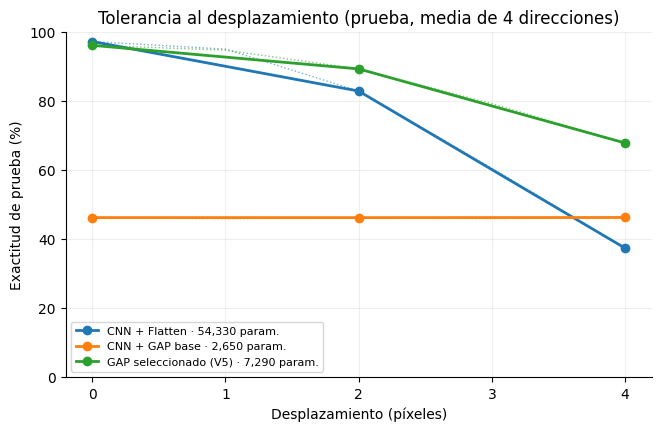

Línea continua: 0, 2 y 4 px (lo que pide la tarea). Línea punteada: incluye 1 y 3 px como complemento.


In [9]:
modelos_finales = {
    "CNN + Flatten": modelo_flatten,
    "CNN + GAP base": modelo_gap_base,
    f"GAP seleccionado ({SEL})": modelo_sel,
}
NOMBRE_SEL = f"GAP seleccionado ({SEL})"
DISTANCIAS = (0, 2, 4)
DISTANCIAS_COMPLEMENTO = (0, 1, 2, 3, 4)

def exactitud(modelo, imagenes):
    return 100 * np.mean(predecir(modelo, imagenes) == y_prueba)

exact_dist = {nombre: {} for nombre in modelos_finales}
exact_dir = []
for d in DISTANCIAS_COMPLEMENTO:
    direcciones = [(0, 0, "centrado")] if d == 0 else [
        (-d, 0, "arriba"), (d, 0, "abajo"), (0, -d, "izquierda"), (0, d, "derecha")]
    for nombre, modelo in modelos_finales.items():
        valores = []
        for dy, dx, etiqueta in direcciones:
            acc = exactitud(modelo, desplazar(X_prueba, dy, dx))
            valores.append(acc)
            exact_dir.append({"Modelo": nombre, "Distancia (px)": d, "Dirección": etiqueta, "Exactitud (%)": acc})
        exact_dist[nombre][d] = float(np.mean(valores))

tabla_desp = pd.DataFrame({n: [exact_dist[n][d] for d in DISTANCIAS] for n in modelos_finales},
                          index=[f"{d} px (%)" for d in DISTANCIAS]).T
tabla_desp["Caída Acc(0px) − Acc(4px) (pp)"] = tabla_desp["0 px (%)"] - tabla_desp["4 px (%)"]
tabla_desp.insert(0, "Parámetros", [parametros_entrenables(m) for m in modelos_finales.values()])
tabla_desp.index.name = "Modelo"
display(tabla_desp.round(2))

fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
for (nombre, color) in zip(modelos_finales, ("C0", "C1", "C2")):
    ax.plot(DISTANCIAS, [exact_dist[nombre][d] for d in DISTANCIAS], marker="o", lw=2,
            color=color, label=f"{nombre} · {parametros_entrenables(modelos_finales[nombre]):,} param.")
    ax.plot(DISTANCIAS_COMPLEMENTO, [exact_dist[nombre][d] for d in DISTANCIAS_COMPLEMENTO],
            ls=":", lw=1, color=color, alpha=0.6)
ax.set(title="Tolerancia al desplazamiento (prueba, media de 4 direcciones)",
       xlabel="Desplazamiento (píxeles)", ylabel="Exactitud de prueba (%)",
       xticks=DISTANCIAS_COMPLEMENTO, ylim=(0, 100))
ax.legend(fontsize=8, loc="lower left")
ax.grid(alpha=0.2)
plt.show()
print("Línea continua: 0, 2 y 4 px (lo que pide la tarea). Línea punteada: incluye 1 y 3 px como complemento.")

## 6. Conclusiones

El siguiente texto se genera con los resultados de esta ejecución. Para decidir que la diferencia entre dos modelos es **apreciable** se exige que supere **2 puntos porcentuales**. Con 2000 imágenes de prueba, el error estándar de una exactitud cercana al 90 % es de unos 0.7 puntos, así que 2 puntos dejan margen frente a la variación por muestreo.

In [11]:
DIF_APRECIABLE = 2.0
miles = lambda x: f"{int(x):,}".replace(",", " ")
firmado = lambda x: ("+" if x >= 0 else "−") + miles(abs(x))
flat, base, sel = "CNN + Flatten", "CNN + GAP base", NOMBRE_SEL

# Cambio más importante: la comparación de una sola decisión con mayor ganancia en validación
mejor = tabla_comp["Δ validación (pp)"].idxmax()
fila = tabla_comp.loc[mejor]
c1 = tabla_comp.loc["C1"]

# Distancia a partir de la cual el GAP seleccionado supera a Flatten de forma apreciable
ventaja = {d: exact_dist[sel][d] - exact_dist[flat][d] for d in DISTANCIAS_COMPLEMENTO}
dist_ventaja = next((d for d in DISTANCIAS_COMPLEMENTO if d > 0 and ventaja[d] > DIF_APRECIABLE), None)
dist_ventaja_tarea = next((d for d in DISTANCIAS if d > 0 and ventaja[d] > DIF_APRECIABLE), None)
caida = {n: exact_dist[n][0] - exact_dist[n][4] for n in modelos_finales}

lineas = []
lineas.append("**¿Cuál fue el cambio más importante para que GAP superara el 95 % en validación?**\n")
lineas.append(
    f"La mayor ganancia de una sola decisión fue **{fila['Decisión'].lower()}** ({mejor}): "
    f"la exactitud de validación pasó de {fila['Val desde (%)']:.2f} % a {fila['Val hacia (%)']:.2f} % "
    f"({fila['Δ validación (pp)']:+.2f} pp) con {firmado(fila['Δ parámetros'])} parámetros, "
    f"y el campo receptivo cambió de {fila['Campo receptivo']} px. "
)
if mejor != "C1":
    lineas.append(
        f"Mover el pooling entre las convoluciones (C1), sin cambiar los parámetros, cambió la validación "
        f"en {c1['Δ validación (pp)']:+.2f} pp, de {c1['Val desde (%)']:.2f} % a {c1['Val hacia (%)']:.2f} %. "
    )
lineas.append(
    f"La variante seleccionada, **{SEL} ({tabla_val.loc[SEL, 'Arquitectura']})**, alcanzó {val_sel:.2f} % en validación "
    f"con un campo receptivo de {tabla_val.loc[SEL, 'Campo receptivo (px)']} px, frente a "
    f"{tabla_val.loc['GAP base', 'Campo receptivo (px)']} px del GAP base. "
)
rf_desde, rf_hacia = (int(x) for x in fila["Campo receptivo"].split(" → "))
if rf_hacia > rf_desde:
    lineas.append(
        "El cambio ganador agranda el campo receptivo antes de GAP, lo que concuerda con la hipótesis: cada canal "
        "llega a ver una parte grande del dígito, y su promedio describe la forma en lugar de solo contar trazos.\n"
    )
else:
    lineas.append(
        "El cambio ganador no modifica el campo receptivo, sino la capacidad (número de filtros). La hipótesis del "
        "campo receptivo se evalúa entonces con C1 a C3, que sí lo cambian.\n"
    )
lineas.append("**¿Cuántos parámetros ahorraste frente a Flatten?**\n")
lineas.append(
    f"El GAP seleccionado usa **{miles(params_sel)} parámetros** frente a {miles(PARAMS_FLATTEN)} de Flatten. "
    f"Ahorra **{miles(ahorro)} parámetros ({100 * ahorro / PARAMS_FLATTEN:.1f} %)**, es decir, es "
    f"{PARAMS_FLATTEN / params_sel:.1f} veces más pequeño. Su validación queda "
    f"{val_sel - 100 * hist_flatten['val_accuracy'][-1]:+.2f} pp respecto a Flatten "
    f"({100 * hist_flatten['val_accuracy'][-1]:.2f} %).\n"
)
lineas.append("**¿Tu GAP seleccionado reconoce mejor los dígitos desplazados que Flatten? ¿A partir de qué distancia?**\n")
lineas.append(
    f"A 0 px, Flatten obtiene {exact_dist[flat][0]:.2f} % y el GAP seleccionado {exact_dist[sel][0]:.2f} %. "
    f"A 2 px obtienen {exact_dist[flat][2]:.2f} % y {exact_dist[sel][2]:.2f} %. "
    f"A 4 px obtienen {exact_dist[flat][4]:.2f} % y {exact_dist[sel][4]:.2f} %. "
    f"Las caídas Acc(0px) − Acc(4px) son {caida[flat]:.2f} pp para Flatten, {caida[base]:.2f} pp para el GAP base "
    f"y {caida[sel]:.2f} pp para el GAP seleccionado. "
)
if abs(ventaja[0]) <= DIF_APRECIABLE:
    lineas.append(f"Centrados, los dos modelos quedan a menos de {DIF_APRECIABLE:.0f} pp ({ventaja[0]:+.2f} pp). ")
elif ventaja[0] < 0:
    lineas.append(f"Centrados, Flatten es mejor por {-ventaja[0]:.2f} pp. ")
else:
    lineas.append(f"El GAP seleccionado ya es mejor sin desplazamiento, por {ventaja[0]:.2f} pp. ")
if dist_ventaja is None:
    lineas.append(f"Con desplazamiento, el GAP seleccionado **no** supera a Flatten por más de {DIF_APRECIABLE:.0f} pp en ninguna distancia.\n")
else:
    texto_tarea = (f"Entre las distancias que pide la tarea (2 y 4 px), la diferencia ya es apreciable a {dist_ventaja_tarea} px. "
                   if dist_ventaja_tarea is not None else "")
    lineas.append(
        f"**Sí**: con desplazamiento, el GAP seleccionado supera a Flatten por más de {DIF_APRECIABLE:.0f} pp desde "
        f"**{dist_ventaja} px** ({exact_dist[sel][dist_ventaja]:.2f} % frente a {exact_dist[flat][dist_ventaja]:.2f} %, "
        f"una ventaja de {ventaja[dist_ventaja]:.2f} pp). {texto_tarea}"
        f"A 4 px la ventaja es de {ventaja[4]:.2f} pp.\n"
    )
lineas.append(
    f"La caída por sí sola no basta para comparar modelos. La caída del GAP base es de {caida[base]:.2f} pp, "
    f"pero a 4 px conserva {exact_dist[base][4]:.2f} %, limitado por su exactitud inicial de {exact_dist[base][0]:.2f} %. "
    f"Lo que importa es la exactitud que queda: a 4 px, el GAP seleccionado conserva {exact_dist[sel][4]:.2f} %, frente a {exact_dist[flat][4]:.2f} % "
    f"de Flatten y {exact_dist[base][4]:.2f} % del GAP base. Flatten asocia cada peso de la capa densa a una posición "
    f"fija, así que un dígito desplazado activa pesos que nunca vieron ese patrón en ese lugar. GAP descarta la "
    f"posición al promediar, y la convolución y el max pooling, que son equivariantes a la traslación, hacen que los "
    f"mapas solo se muevan cuando se mueve el dígito. Esto no es invarianza perfecta: el pooling de stride 2 y los "
    f"bordes con padding hacen que un desplazamiento que no es múltiplo del paso total cambie un poco las activaciones.\n"
)
display(Markdown("\n".join(lineas)))

**¿Cuál fue el cambio más importante para que GAP superara el 95 % en validación?**

La mayor ganancia de una sola decisión fue **añadir una tercera etapa** (C3a): la exactitud de validación pasó de 61.80 % a 90.07 % (+28.27 pp) con +2 320 parámetros, y el campo receptivo cambió de 10 → 22 px. 
Mover el pooling entre las convoluciones (C1), sin cambiar los parámetros, cambió la validación en +17.87 pp, de 43.93 % a 61.80 %. 
La variante seleccionada, **V5 (16 | 16 | 16 | 16)**, alcanzó 95.53 % en validación con un campo receptivo de 46 px, frente a 6 px del GAP base. 
El cambio ganador agranda el campo receptivo antes de GAP, lo que concuerda con la hipótesis: cada canal llega a ver una parte grande del dígito, y su promedio describe la forma en lugar de solo contar trazos.

**¿Cuántos parámetros ahorraste frente a Flatten?**

El GAP seleccionado usa **7 290 parámetros** frente a 54 330 de Flatten. Ahorra **47 040 parámetros (86.6 %)**, es decir, es 7.5 veces más pequeño. Su validación queda -1.27 pp respecto a Flatten (96.80 %).

**¿Tu GAP seleccionado reconoce mejor los dígitos desplazados que Flatten? ¿A partir de qué distancia?**

A 0 px, Flatten obtiene 97.15 % y el GAP seleccionado 96.05 %. A 2 px obtienen 82.81 % y 89.22 %. A 4 px obtienen 37.36 % y 67.79 %. Las caídas Acc(0px) − Acc(4px) son 59.79 pp para Flatten, -0.02 pp para el GAP base y 28.26 pp para el GAP seleccionado. 
Centrados, los dos modelos quedan a menos de 2 pp (-1.10 pp). 
**Sí**: con desplazamiento, el GAP seleccionado supera a Flatten por más de 2 pp desde **2 px** (89.22 % frente a 82.81 %, una ventaja de 6.41 pp). Entre las distancias que pide la tarea (2 y 4 px), la diferencia ya es apreciable a 2 px. A 4 px la ventaja es de 30.42 pp.

La caída por sí sola no basta para comparar modelos. La caída del GAP base es de -0.02 pp, pero a 4 px conserva 46.23 %, limitado por su exactitud inicial de 46.20 %. Lo que importa es la exactitud que queda: a 4 px, el GAP seleccionado conserva 67.79 %, frente a 37.36 % de Flatten y 46.23 % del GAP base. Flatten asocia cada peso de la capa densa a una posición fija, así que un dígito desplazado activa pesos que nunca vieron ese patrón en ese lugar. GAP descarta la posición al promediar, y la convolución y el max pooling, que son equivariantes a la traslación, hacen que los mapas solo se muevan cuando se mueve el dígito. Esto no es invarianza perfecta: el pooling de stride 2 y los bordes con padding hacen que un desplazamiento que no es múltiplo del paso total cambie un poco las activaciones.


### Interpretación de los resultados

**¿Cuál fue el cambio más importante para que GAP superara el 95 % en validación?** Fue **poner un *max pooling* después de cada convolución**, no añadir parámetros. La prueba más clara es comparar V2 (`16-16-16-16`) con V5 (`16 | 16 | 16 | 16`). Las dos tienen cuatro convoluciones de 16 filtros y exactamente 7 290 parámetros, y solo cambia la ubicación del pooling. V2 llega a 61.20 % y V5 a 95.53 %. Las comparaciones C1 y C2 dicen lo mismo sin cambiar los parámetros: C1 gana +17.87 pp (de 43.93 % a 61.80 %) y C2 gana +27.13 pp (de 61.20 % a 88.33 %). Añadir etapas (C3a, +28.27 pp; C3b, +5.47 pp) funciona por la misma razón, porque cada etapa trae su propio pooling. El campo receptivo de los canales finales pasa de 6 px en el GAP base a 46 px en V5. Con 46 px, cada canal ve el dígito completo y GAP promedia detectores de forma en lugar de detectores de trazos. Así se confirma la hipótesis del apartado 3.

Ensanchar la red rinde mucho menos. Pasar las etapas profundas de 16 a 32 filtros (C6) gana +3.40 pp a cambio de 9 408 parámetros más. V11 (`16 | 32 | 64`) usa 23 946 parámetros, más del triple que V5, y queda por debajo (95.33 %). Con la primera convolución, cambiar de 8 a 16 filtros (C4, −1.47 pp) o de kernel 3 × 3 a 5 × 5 (C5, +0.40 pp) da diferencias de una a dos decenas de imágenes de validación, que no se distinguen del ruido de una sola semilla. En todas las variantes GAP, la exactitud de entrenamiento queda casi igual a la de validación; en V5 es 95.91 % frente a 95.53 %. Esto indica que el límite es la capacidad y el presupuesto de 20 épocas, no el sobreajuste.

**Advertencia.** V5 supera el umbral por 0.53 pp, unas 8 imágenes de 1 500, en una sola ejecución. La siguiente variante más pequeña, V8, se queda en 93.47 %. Con otra semilla la selección podría cambiar, aunque V11 también supera el 95 %.

**¿Cuántos parámetros ahorraste frente a Flatten?** V5 usa 7 290 parámetros frente a 54 330. El ahorro es de **47 040 parámetros (86.6 %)**, es decir, 7.5 veces menos. A cambio pierde 1.27 pp en validación (95.53 % frente a 96.80 %).

**¿Tu GAP seleccionado reconoce mejor los dígitos desplazados que Flatten?** Sí, desde **2 px**. Centrados, Flatten es ligeramente mejor (97.15 % frente a 96.05 %, una diferencia de −1.10 pp, dentro del margen de 2 pp). A 1 px la ventaja de V5 todavía no llega a 2 pp. A 2 px, V5 obtiene 89.22 % y Flatten 82.81 % (+6.41 pp). A 4 px, V5 obtiene 67.79 % y Flatten 37.36 % (+30.42 pp). La caída de V5 es de 28.26 pp, menos de la mitad de los 59.79 pp de Flatten. El GAP base casi no cae (−0.02 pp), pero se queda en 46 % en todas las distancias. A 4 px, V5 conserva 21.6 puntos más que el GAP base y 30.4 más que Flatten.

V5 tampoco es invariante: pierde 28 pp a 4 px. Sus cuatro poolings dan un paso total de 16 píxeles, así que un desplazamiento de 4 px cambia qué píxeles caen en cada ventana de 2 × 2. Además, el pooling de 9 × 9 a 4 × 4 descarta la última fila y la última columna, y esa pérdida depende de la posición del dígito. El campo receptivo de 46 px también es mayor que la imagen de 36 px, de modo que el relleno con ceros del borde influye en las activaciones. Ningún modelo vio dígitos desplazados durante el entrenamiento. Aumentar los datos con traslaciones probablemente reduciría la caída, pero eso ya queda fuera de esta tarea.

### Declaración de uso de IA

Se utilizó el asistente de inteligencia artificial Claude (Anthropic) en la elaboración de este notebook. La autora revisó el contenido y es responsable de su exactitud.